In [4]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
PROJECT_DIR = Path.cwd().parent

DATASET_DIR = PROJECT_DIR / "dataset"
IMAGE_DIR = DATASET_DIR / "train_images"
MODEL_DIR = PROJECT_DIR / "models"

IMG_SIZE = 224
BATCH_SIZE = 8

print("Project directory:", PROJECT_DIR)
print("Model directory:", MODEL_DIR)

Project directory: c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection
Model directory: c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\models


In [6]:
val_df = pd.read_csv(DATASET_DIR / "val_split.csv")

print("Validation images:", len(val_df))
print("\nClass distribution:")
print(val_df["diagnosis"].value_counts().sort_index())

Validation images: 733

Class distribution:
diagnosis
0    361
1     74
2    200
3     39
4     59
Name: count, dtype: int64


In [7]:
def load_eval_image(image_path, label, model_type):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_png(
        image,
        channels=3
    )

    image = tf.image.resize_with_pad(
        image,
        IMG_SIZE,
        IMG_SIZE,
        antialias=True
    )

    image = tf.cast(image, tf.float32)

    if model_type == "mobilenet":
        image = preprocess_input(image)

    else:
        image = image / 255.0

    label = tf.cast(label, tf.int32)

    return image, label

In [8]:
def create_eval_dataset(dataframe, model_type):

    image_paths = [
        str(IMAGE_DIR / f"{image_id}.png")
        for image_id in dataframe["id_code"]
    ]

    labels = dataframe["diagnosis"].values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    dataset = dataset.map(
        lambda path, label: load_eval_image(
            path, label, model_type
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


cnn_val_ds = create_eval_dataset(val_df, "cnn")

mobilenet_val_ds = create_eval_dataset(
    val_df, "mobilenet"
)

y_true = val_df["diagnosis"].values

print("Evaluation datasets created successfully!")

Evaluation datasets created successfully!


In [9]:
cnn_model = tf.keras.models.load_model(
    MODEL_DIR / "cnn_baseline_best.keras"
)

mobilenet_model = tf.keras.models.load_model(
    MODEL_DIR / "mobilenetv2_best.keras"
)

finetuned_model = tf.keras.models.load_model(
    MODEL_DIR / "mobilenetv2_finetuned_best.keras"
)

print("All three models loaded successfully!")

All three models loaded successfully!


In [14]:
cnn_prob = cnn_model.predict(cnn_val_ds)

mobilenet_prob = mobilenet_model.predict(
    mobilenet_val_ds
)

finetuned_prob = finetuned_model.predict(
    mobilenet_val_ds
)

cnn_pred = np.argmax(cnn_prob, axis=1)

mobilenet_pred = np.argmax(mobilenet_prob, axis=1)

finetuned_pred = np.argmax(finetuned_prob, axis=1)

print("Predictions generated successfully!")

71/92 ━━━━━━━━━━━━━━━━━━━━ 2s 119ms/step

KeyboardInterrupt: 

In [15]:
models_predictions = {
    "Baseline CNN": cnn_pred,
    "MobileNetV2": mobilenet_pred,
    "Fine-tuned MobileNetV2": finetuned_pred
}

comparison = []

for model_name, predictions in models_predictions.items():

    comparison.append({

        "Model": model_name,

        "Accuracy": accuracy_score(
            y_true, predictions
        ),

        "Macro Precision": precision_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),

        "Macro F1": f1_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true, predictions,
            average="weighted", zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison)

comparison_df.round(4)

NameError: name 'cnn_pred' is not defined

In [16]:
comparison_df.set_index("Model")[
    ["Accuracy", "Macro F1", "Weighted F1"]
].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("Comparison of Diabetic Retinopathy Models")

plt.ylabel("Score")

plt.xlabel("Model")

plt.xticks(rotation=15)

plt.grid(axis="y", alpha=0.3)

plt.legend(loc="lower right")

plt.tight_layout()

plt.show()

NameError: name 'comparison_df' is not defined

In [ ]:

# Project paths
PROJECT_DIR = Path.cwd().parent

DATASET_DIR = PROJECT_DIR / "dataset"
IMAGE_DIR = DATASET_DIR / "train_images"
MODEL_DIR = PROJECT_DIR / "models"

# Grad-CAM output directory
GRADCAM_DIR = PROJECT_DIR / "outputs" / "gradcam"
GRADCAM_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 224

# Load the best fine-tuned model
finetuned_model = tf.keras.models.load_model(
    MODEL_DIR / "mobilenetv2_finetuned_best.keras"
)

# Load validation data
val_df = pd.read_csv(
    DATASET_DIR / "val_split.csv"
)

print("Fine-tuned model loaded successfully!")
print("Validation images:", len(val_df))
print("Grad-CAM output directory:", GRADCAM_DIR)

Fine-tuned model loaded successfully!
Validation images: 733
Grad-CAM output directory: c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\outputs\gradcam


In [ ]:
# Find the nested MobileNetV2 model
base_model = None

for layer in finetuned_model.layers:

    if hasattr(layer, "get_layer"):

        try:
            layer.get_layer("out_relu")
            base_model = layer
            break

        except (ValueError, AttributeError):
            continue

if base_model is None:
    raise ValueError("MobileNetV2 backbone could not be located.")

# Locate the final convolutional activation layer
last_conv_layer = base_model.get_layer("out_relu")

print("Backbone:", base_model.name)
print("Selected convolutional layer:", last_conv_layer.name)
print("Feature map shape:", last_conv_layer.output.shape)

Backbone: mobilenetv2_1.00_224
Selected convolutional layer: out_relu
Feature map shape: (None, 7, 7, 1280)


In [ ]:
# Create a model that extracts convolutional features
feature_extractor = tf.keras.Model(
    inputs=base_model.input,
    outputs=last_conv_layer.output
)

# Find the position of the MobileNetV2 backbone
base_index = finetuned_model.layers.index(base_model)

# Get classification layers following MobileNetV2
classifier_layers = finetuned_model.layers[base_index + 1:]

# Create a new input
grad_input = tf.keras.Input(
    shape=(224, 224, 3)
)

# Extract feature maps
conv_outputs = feature_extractor(
    grad_input,
    training=False
)

# Pass features through the classification head
x = conv_outputs

for layer in classifier_layers:
    x = layer(x)

# Create Grad-CAM model
grad_model = tf.keras.Model(
    inputs=grad_input,
    outputs=[conv_outputs, x]
)

print("Grad-CAM model created successfully!")

Grad-CAM model created successfully!


In [ ]:
def preprocess_gradcam_image(image_path):

    # Read image
    image_bytes = tf.io.read_file(str(image_path))

    # Decode PNG
    image = tf.image.decode_png(
        image_bytes,
        channels=3
    )

    # Resize while preserving aspect ratio
    image = tf.image.resize_with_pad(
        image,
        224,
        224,
        antialias=True
    )

    image = tf.cast(image, tf.float32)

    # Prepare original image for visualization
    display_image = tf.clip_by_value(
        image / 255.0,
        0.0,
        1.0
    )

    # Apply MobileNetV2 preprocessing
    processed_image = preprocess_input(image)

    # Add batch dimension
    img_array = tf.expand_dims(
        processed_image,
        axis=0
    )

    return display_image.numpy(), img_array

In [ ]:
def make_gradcam_heatmap(
    img_array,
    grad_model,
    class_index=None
):

    # Calculate gradients
    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            img_array,
            training=False
        )

        # Select predicted class if no class is specified
        if class_index is None:

            class_index = tf.argmax(
                predictions[0]
            )

        # Score of the selected class
        class_score = predictions[:, class_index]

    # Calculate gradients
    grads = tape.gradient(
        class_score,
        conv_outputs
    )

    if grads is None:
        raise RuntimeError(
            "Gradients could not be calculated."
        )

    # Average gradients across spatial dimensions
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    # Remove batch dimension
    feature_maps = conv_outputs[0]

    weights = pooled_grads[0]

    # Calculate weighted combination of feature maps
    heatmap = tf.reduce_sum(
        feature_maps * weights,
        axis=-1
    )

    # Retain positive contributions
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize heatmap
    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / (max_value + tf.keras.backend.epsilon()),
        tf.zeros_like(heatmap)
    )

    return (
        heatmap.numpy(),
        predictions[0].numpy(),
        int(class_index.numpy())
    )


print("Grad-CAM function created successfully!")

Grad-CAM function created successfully!


In [ ]:
class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

# Select one Severe DR image
sample = val_df[
    val_df["diagnosis"] == 3
].iloc[0]

image_id = sample["id_code"]

actual_class = int(
    sample["diagnosis"]
)

image_path = IMAGE_DIR / f"{image_id}.png"

print("Image ID:", image_id)
print("Actual DR grade:", class_names[actual_class])
print("Image exists:", image_path.exists())

Image ID: 7b29e3783919
Actual DR grade: Severe
Image exists: True


In [ ]:
# Preprocess retinal image
display_image, img_array = preprocess_gradcam_image(
    image_path
)

# Generate Grad-CAM
heatmap, probabilities, selected_class = make_gradcam_heatmap(
    img_array,
    grad_model
)

# Find predicted class
predicted_class = int(
    np.argmax(probabilities)
)

# Obtain model score
prediction_score = float(
    probabilities[predicted_class]
)

print("--------------------------------")
print("GRAD-CAM PREDICTION RESULTS")
print("--------------------------------")

print("Actual grade:", class_names[actual_class])

print("Predicted grade:", class_names[predicted_class])

print(
    "Softmax score:",
    round(prediction_score * 100, 2),
    "%"
)

print("--------------------------------")
print("Heatmap generated successfully!")

--------------------------------
GRAD-CAM PREDICTION RESULTS
--------------------------------
Actual grade: Severe
Predicted grade: Severe
Softmax score: 61.67 %
--------------------------------
Heatmap generated successfully!


In [ ]:
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (224, 224)
).numpy().squeeze()

print("Original heatmap shape:", heatmap.shape)

print("Resized heatmap shape:", heatmap_resized.shape)

Original heatmap shape: (7, 7)
Resized heatmap shape: (224, 224)


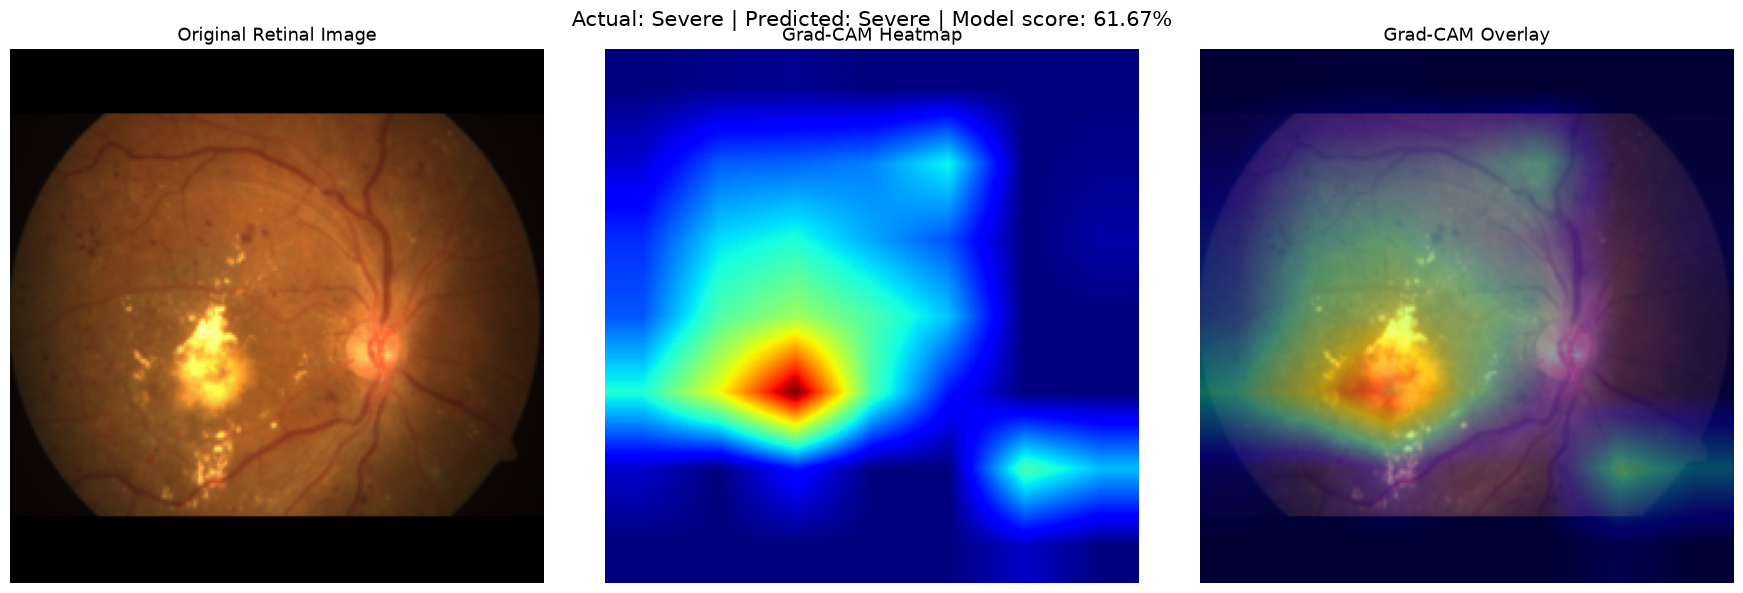

In [ ]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

# Original retinal image
axes[0].imshow(display_image)

axes[0].set_title(
    "Original Retinal Image",
    fontsize=13
)

axes[0].axis("off")


# Grad-CAM heatmap
axes[1].imshow(
    heatmap_resized,
    cmap="jet"
)

axes[1].set_title(
    "Grad-CAM Heatmap",
    fontsize=13
)

axes[1].axis("off")


# Heatmap overlay
axes[2].imshow(display_image)

axes[2].imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=1
)

axes[2].set_title(
    "Grad-CAM Overlay",
    fontsize=13
)

axes[2].axis("off")


fig.suptitle(
    f"Actual: {class_names[actual_class]} | "
    f"Predicted: {class_names[predicted_class]} | "
    f"Model score: {prediction_score * 100:.2f}%",
    fontsize=15
)

plt.tight_layout()

plt.show()

In [ ]:
output_path = GRADCAM_DIR / f"{image_id}_gradcam.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Grad-CAM visualization saved!")
print("File:", output_path)

Grad-CAM visualization saved!
File: c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\outputs\gradcam\7b29e3783919_gradcam.png


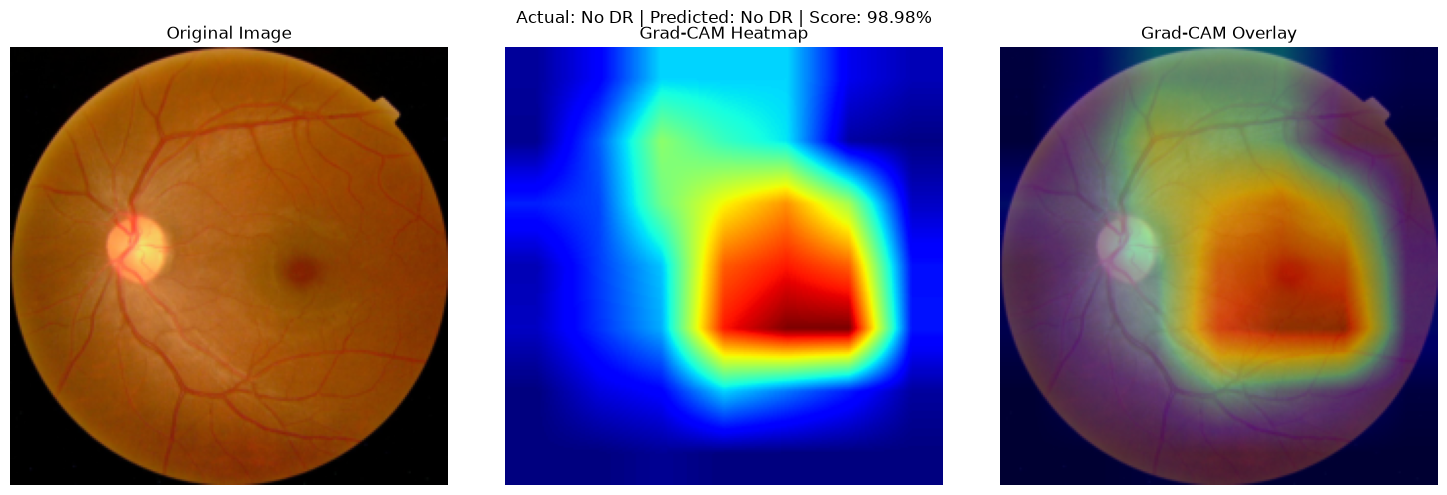

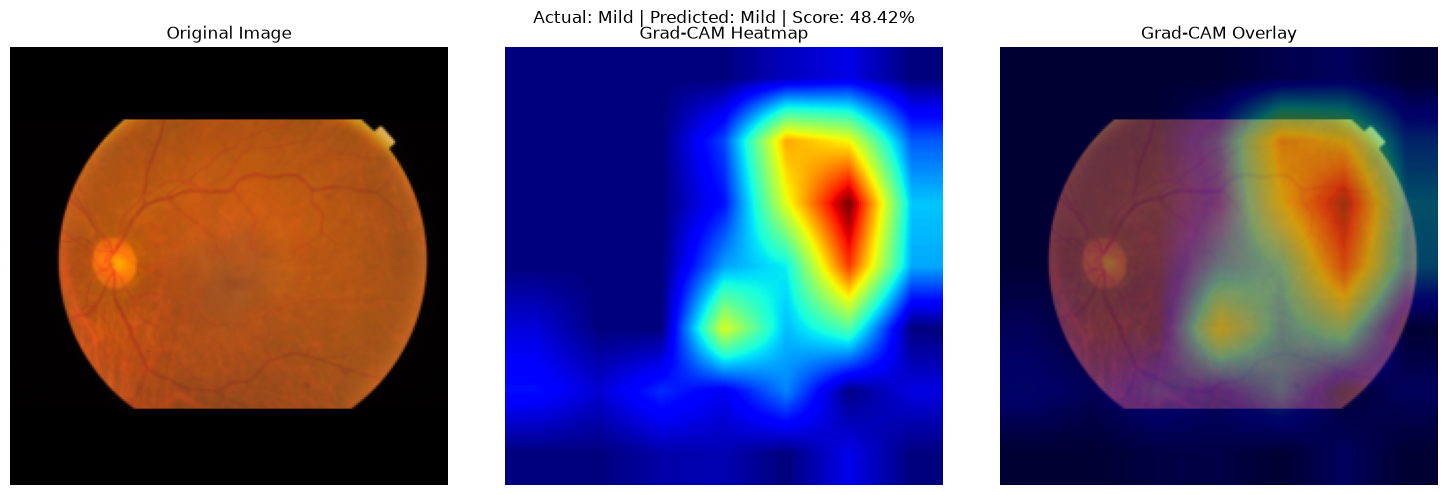

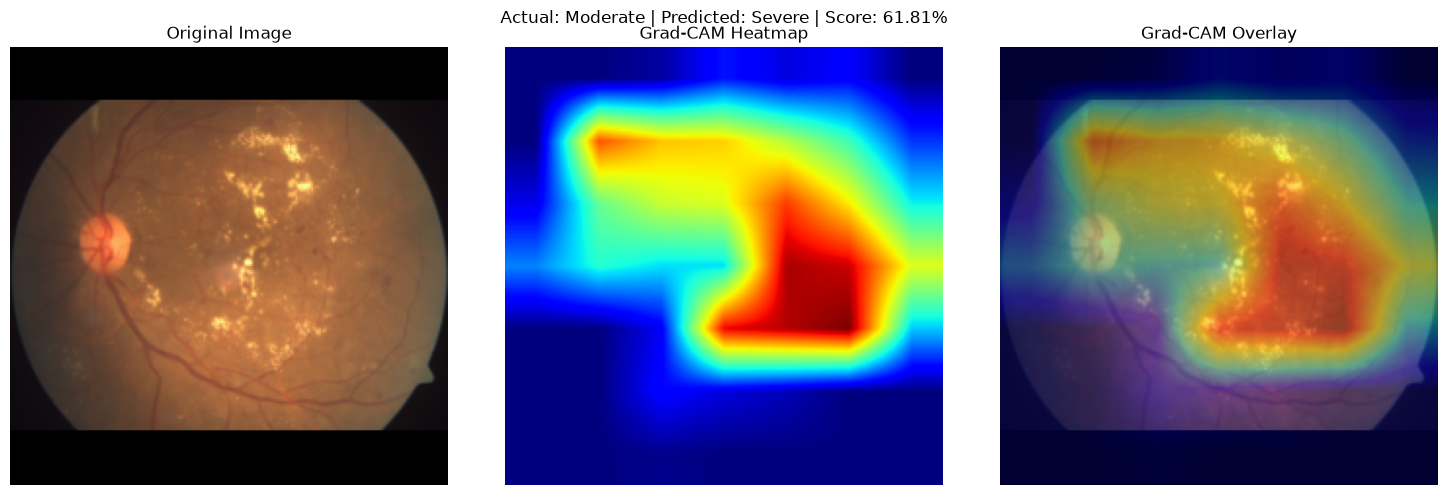

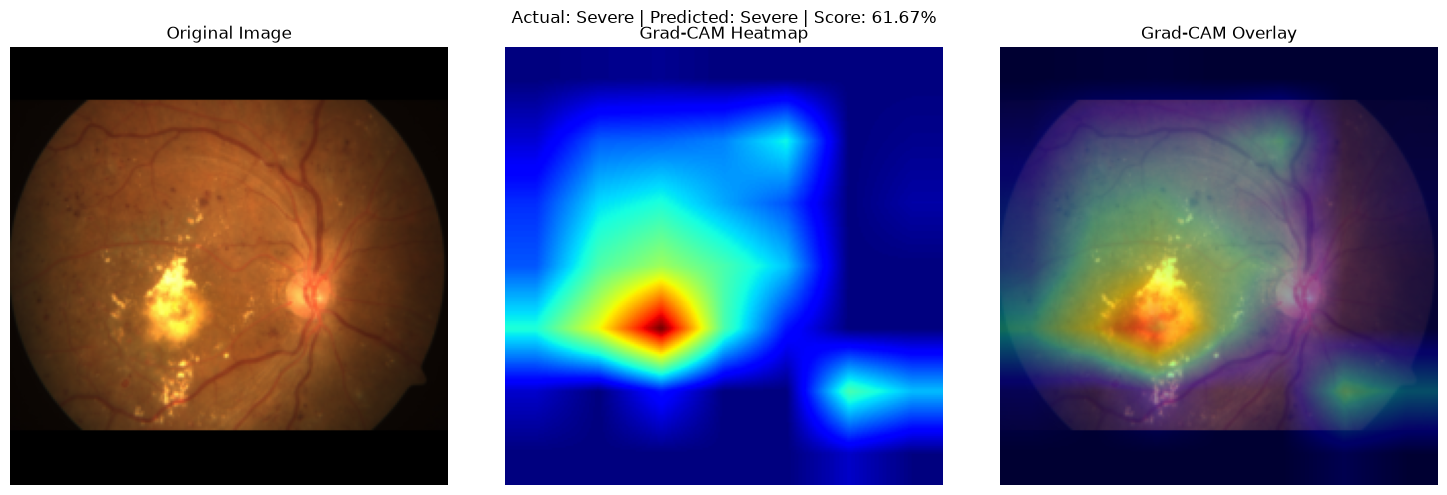

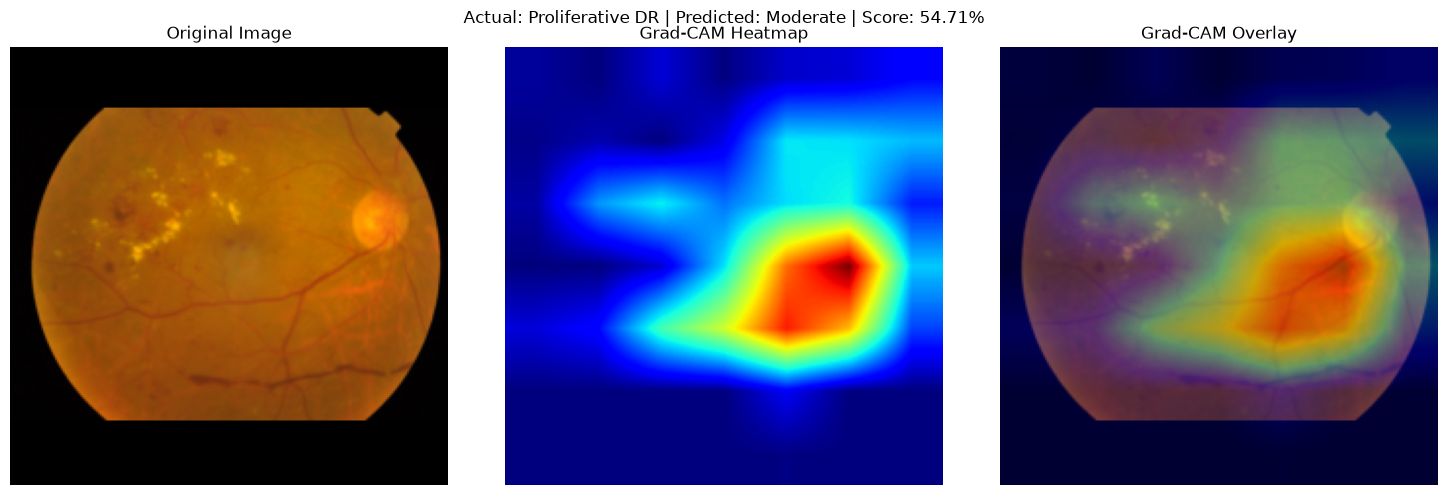

All five Grad-CAM examples generated!


In [ ]:
for class_id in range(5):

    # Select one image from each class
    sample = val_df[
        val_df["diagnosis"] == class_id
    ].iloc[0]

    image_id = sample["id_code"]

    actual_class = int(sample["diagnosis"])

    image_path = IMAGE_DIR / f"{image_id}.png"

    # Preprocess image
    display_image, img_array = preprocess_gradcam_image(
        image_path
    )

    # Generate Grad-CAM
    heatmap, probabilities, _ = make_gradcam_heatmap(
        img_array,
        grad_model
    )

    predicted_class = int(np.argmax(probabilities))

    # Resize heatmap
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    score = float(probabilities[predicted_class])

    # Plot
    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 5)
    )

    axes[0].imshow(display_image)
    axes[0].set_title("Original Image")
    axes[0].axis("off")

    axes[1].imshow(
        heatmap_resized,
        cmap="jet"
    )
    axes[1].set_title("Grad-CAM Heatmap")
    axes[1].axis("off")

    axes[2].imshow(display_image)

    axes[2].imshow(
        heatmap_resized,
        cmap="jet",
        alpha=0.4
    )

    axes[2].set_title("Grad-CAM Overlay")
    axes[2].axis("off")

    plt.suptitle(
        f"Actual: {class_names[actual_class]} | "
        f"Predicted: {class_names[predicted_class]} | "
        f"Score: {score * 100:.2f}%"
    )

    plt.tight_layout()

    # Save
    save_path = GRADCAM_DIR / f"{image_id}_gradcam.png"

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

print("All five Grad-CAM examples generated!")

In [ ]:
metadata = pd.read_csv(
    DATASET_DIR / "train.csv"
)

image_id = "fed5bb685832"

result = metadata[
    metadata["id_code"] == image_id
]

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

if not result.empty:

    actual_class = int(result.iloc[0]["diagnosis"])

    print("Image ID:", image_id)
    print("Actual DR Grade:", class_names[actual_class])

else:

    print("Image not found in the dataset.")

Image ID: fed5bb685832
Actual DR Grade: No DR


In [ ]:
for class_id in range(5):

    sample = val_df[
        val_df["diagnosis"] == class_id
    ].sample(1, random_state=42).iloc[0]

    print(
        class_names[class_id],
        "→",
        sample["id_code"] + ".png"
    )

No DR → 233d948e2544.png
Mild → 51131b48f9d4.png
Moderate → 9f436886e056.png
Severe → 24b87f744598.png
Proliferative DR → 61bbc11fe503.png


In [ ]:
def check_single_image(image_id):

    image_path = IMAGE_DIR / f"{image_id}.png"

    image = tf.io.read_file(str(image_path))

    image = tf.image.decode_png(
        image,
        channels=3
    )

    image = tf.image.resize_with_pad(
        image,
        224,
        224,
        antialias=True
    )

    image = tf.cast(image, tf.float32)

    image = preprocess_input(image)

    image = tf.expand_dims(image, axis=0)

    probabilities = finetuned_model.predict(
        image,
        verbose=0
    )[0]

    predicted_class = int(np.argmax(probabilities))

    return (
        class_names[predicted_class],
        round(float(probabilities[predicted_class]) * 100, 2)
    )

In [ ]:
for class_id in range(5):

    sample = val_df[
        val_df["diagnosis"] == class_id
    ].sample(1, random_state=42).iloc[0]

    image_id = sample["id_code"]

    predicted, score = check_single_image(image_id)

    print("----------------------------------")
    print("Image ID:", image_id)
    print("Actual:", class_names[class_id])
    print("Notebook prediction:", predicted)
    print("Model score:", score, "%")

----------------------------------
Image ID: 233d948e2544
Actual: No DR
Notebook prediction: No DR
Model score: 56.94 %
----------------------------------
Image ID: 51131b48f9d4
Actual: Mild
Notebook prediction: Moderate
Model score: 54.87 %
----------------------------------
Image ID: 9f436886e056
Actual: Moderate
Notebook prediction: Proliferative DR
Model score: 68.73 %
----------------------------------
Image ID: 24b87f744598
Actual: Severe
Notebook prediction: Severe
Model score: 39.73 %
----------------------------------
Image ID: 61bbc11fe503
Actual: Proliferative DR
Notebook prediction: Moderate
Model score: 54.71 %


In [1]:
required_variables = [
    "tf",
    "np",
    "layers",
    "PROJECT_DIR",
    "DATASET_DIR",
    "IMAGE_DIR",
    "MODEL_DIR",
    "train_df",
    "val_df",
    "train_ds",
    "val_ds",
    "class_weights"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    print("Missing variables:", missing_variables)
else:
    print("All required variables are available!")
    print("Ready for the augmentation experiment.")

Missing variables: ['tf', 'np', 'layers', 'PROJECT_DIR', 'DATASET_DIR', 'IMAGE_DIR', 'MODEL_DIR', 'train_df', 'val_df', 'train_ds', 'val_ds', 'class_weights']


In [4]:
# ==========================================
# RESTORE PROJECT ENVIRONMENT
# No model training happens in this cell.
# ==========================================

import pandas as pd
import numpy as np
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import layers, models
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.utils.class_weight import compute_class_weight

# 1. Project paths
PROJECT_DIR = Path.cwd().parent
DATASET_DIR = PROJECT_DIR / "dataset"
IMAGE_DIR = DATASET_DIR / "train_images"
MODEL_DIR = PROJECT_DIR / "models"

# 2. Load existing dataset splits
train_df = pd.read_csv(DATASET_DIR / "train_split.csv")
val_df = pd.read_csv(DATASET_DIR / "val_split.csv")

# 3. Image configuration
IMG_SIZE = 224
BATCH_SIZE = 8

# 4. Restore preprocessing function
def load_mobilenet_image(image_path, label):

    image = tf.io.read_file(image_path)
    image = tf.image.decode_png(image, channels=3)

    image = tf.image.resize_with_pad(
        image, IMG_SIZE, IMG_SIZE, antialias=True
    )

    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)

    return image, tf.cast(label, tf.int32)


# 5. Restore dataset creation function
def create_mobilenet_dataset(dataframe, training=False):

    image_paths = [
        str(IMAGE_DIR / f"{image_id}.png")
        for image_id in dataframe["id_code"]
    ]

    labels = dataframe["diagnosis"].values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(image_paths),
            seed=42
        )

    dataset = dataset.map(
        load_mobilenet_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# 6. Recreate datasets
train_ds = create_mobilenet_dataset(train_df, training=True)
val_ds = create_mobilenet_dataset(val_df, training=False)

# 7. Restore class weights
classes = np.unique(train_df["diagnosis"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["diagnosis"]
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

# 8. Load previously trained model
augmentation_base_model = tf.keras.models.load_model(
    MODEL_DIR / "mobilenetv2_finetuned_best.keras"
)

print("====================================")
print("PROJECT ENVIRONMENT RESTORED")
print("====================================")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Existing trained model loaded.")
print("No previous training was repeated.")
print("Ready for data augmentation experiment.")

PROJECT ENVIRONMENT RESTORED
Training images: 2929
Validation images: 733
Existing trained model loaded.
No previous training was repeated.
Ready for data augmentation experiment.


In [5]:
# Find the MobileNetV2 backbone
base_model = next(
    layer for layer in augmentation_base_model.layers
    if isinstance(layer, tf.keras.Model)
    and any(l.name == "out_relu" for l in layer.layers)
)

base_model.trainable = True

# Fine-tune only the last 20 layers
fine_tune_at = len(base_model.layers) - 20

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_at:]:

    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

    else:
        layer.trainable = True

print("Backbone configured successfully!")
print(
    "Trainable backbone layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Backbone configured successfully!
Trainable backbone layers: 13


In [6]:
data_augmentation = tf.keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(
        0.05,
        fill_mode="reflect"
    ),

    layers.RandomZoom(
        0.08,
        fill_mode="reflect"
    )

], name="retinal_data_augmentation")

print("Data augmentation configured!")

Data augmentation configured!


In [7]:
inputs = layers.Input(shape=(224, 224, 3))

# Apply augmentation during training
augmented_images = data_augmentation(inputs)

# Pass augmented images through the existing trained model
outputs = augmentation_base_model(augmented_images)

augmented_model = models.Model(
    inputs=inputs,
    outputs=outputs
)

print("Augmented MobileNetV2 model created!")

Augmented MobileNetV2 model created!


In [8]:
augmented_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.000005
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=["accuracy"]
)

print("Augmented model compiled successfully!")

augmented_model.summary()

Augmented model compiled successfully!


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ retinal_data_augmentation       │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional (Functional)         │ (None, 5)              │     2,264,389 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 1,201,285 (4.58 MB)

 Non-trainable params: 1,063,104 (4.06 MB)

In [ ]:
augmentation_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=0.000001,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            MODEL_DIR / "mobilenetv2_augmented_best.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("Training callbacks configured for 8 epochs!")

Training callbacks configured!


In [10]:
augmentation_history = augmented_model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=8,

    class_weight=class_weights,

    callbacks=augmentation_callbacks
)

Epoch 1/8


c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


367/367 ━━━━━━━━━━━━━━━━━━━━ 89s 229ms/step - accuracy: 0.7296 - loss: 0.8453 - val_accuracy: 0.7367 - val_loss: 0.7297 - learning_rate: 5.0000e-06
Epoch 2/8
367/367 ━━━━━━━━━━━━━━━━━━━━ 78s 213ms/step - accuracy: 0.7484 - loss: 0.8081 - val_accuracy: 0.7476 - val_loss: 0.6832 - learning_rate: 5.0000e-06
Epoch 3/8
367/367 ━━━━━━━━━━━━━━━━━━━━ 80s 216ms/step - accuracy: 0.7477 - loss: 0.7827 - val_accuracy: 0.7408 - val_loss: 0.7145 - learning_rate: 5.0000e-06
Epoch 4/8
367/367 ━━━━━━━━━━━━━━━━━━━━ 82s 222ms/step - accuracy: 0.7590 - loss: 0.7659 - val_accuracy: 0.7517 - val_loss: 0.6904 - learning_rate: 2.5000e-06


In [11]:
print("Completed epochs:", len(
    augmentation_history.history["loss"]
))

print("\nCallback configuration:")

for callback in augmentation_callbacks:

    print(
        type(callback).__name__,
        "Patience:",
        getattr(callback, "patience", "N/A")
    )

    if isinstance(callback, tf.keras.callbacks.EarlyStopping):

        print("Stopped epoch:", callback.stopped_epoch)
        print("Wait counter:", callback.wait)
        print("Best validation loss:", callback.best)

Completed epochs: 4

Callback configuration:
EarlyStopping Patience: 2
Stopped epoch: 3
Wait counter: 2
Best validation loss: 0.6832393407821655
ReduceLROnPlateau Patience: 1


In [12]:
AUGMENTED_MODEL_PATH = (
    MODEL_DIR / "mobilenetv2_augmented_best.keras"
)

augmentation_base_model.save(
    AUGMENTED_MODEL_PATH
)

print("Augmented experimental model saved!")
print(AUGMENTED_MODEL_PATH)

Augmented experimental model saved!
c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\models\mobilenetv2_augmented_best.keras


In [13]:
augmented_candidate = tf.keras.models.load_model(
    AUGMENTED_MODEL_PATH
)

augmented_prob = augmented_candidate.predict(
    val_ds
)

augmented_pred = np.argmax(
    augmented_prob,
    axis=1
)

from sklearn.metrics import classification_report

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print(
    classification_report(
        val_df["diagnosis"].values,
        augmented_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=class_names,
        zero_division=0
    )
)

92/92 ━━━━━━━━━━━━━━━━━━━━ 15s 150ms/step
                  precision    recall  f1-score   support

           No DR       0.96      0.94      0.95       361
            Mild       0.42      0.68      0.52        74
        Moderate       0.75      0.56      0.64       200
          Severe       0.37      0.59      0.45        39
Proliferative DR       0.49      0.37      0.42        59

        accuracy                           0.75       733
       macro avg       0.60      0.63      0.60       733
    weighted avg       0.78      0.75      0.75       733



In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Load original fine-tuned model
original_model = tf.keras.models.load_model(
    MODEL_DIR / "mobilenetv2_finetuned_best.keras"
)

# Load augmented model
augmented_candidate = tf.keras.models.load_model(
    MODEL_DIR / "mobilenetv2_augmented_best.keras"
)

# Actual labels
y_true = val_df["diagnosis"].values

# Predictions
original_prob = original_model.predict(val_ds)
augmented_prob = augmented_candidate.predict(val_ds)

original_pred = np.argmax(original_prob, axis=1)
augmented_pred = np.argmax(augmented_prob, axis=1)

# Compare metrics
comparison_results = []

for name, predictions in [
    ("Fine-tuned MobileNetV2", original_pred),
    ("Augmented MobileNetV2", augmented_pred)
]:

    comparison_results.append({

        "Model": name,

        "Accuracy": accuracy_score(y_true, predictions),

        "Macro Precision": precision_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),

        "Macro F1": f1_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true, predictions,
            average="weighted", zero_division=0
        )
    })

final_comparison_df = pd.DataFrame(comparison_results)

final_comparison_df.round(4)

92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 179ms/step
92/92 ━━━━━━━━━━━━━━━━━━━━ 16s 164ms/step


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Fine-tuned MobileNetV2,0.7681,0.6123,0.611,0.6093,0.7692
1,Augmented MobileNetV2,0.7476,0.5962,0.629,0.5974,0.7534


In [15]:
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

final_comparison_df.to_csv(
    OUTPUT_DIR / "final_model_comparison.csv",
    index=False
)

print("Final model comparison saved successfully!")

Final model comparison saved successfully!
